# 01 · Análisis exploratorio de datos (CRISP-DM: Comprensión de los datos)

Preguntas guía de la consigna: distribución de clases, desbalance, calidad de las imágenes y variabilidad. Cada sección termina en una decisión de preparación, y las conclusiones están al final.

> Requisitos: `data/processed/index.csv`, `splits.csv` y `crops/` (`python -m src.main download index preprocess`). Tarda alrededor de un minuto.

In [1]:
import sys; sys.path.insert(0, '..')
import warnings; warnings.filterwarnings('ignore')
import pandas as pd, numpy as np, cv2, matplotlib.pyplot as plt
from PIL import Image
from src import config
from src.data.segmentation import load_image, segment, overlay

pd.set_option('display.width', 140)
idx = pd.read_csv(config.INDEX_CSV)   # todas las imágenes etiquetadas
sp = pd.read_csv(config.SPLITS_CSV)   # las que se usan: tope por carpeta, segmentación y partición
print(f'index.csv: {len(idx):,} imágenes | splits.csv (usadas): {len(sp):,}')

index.csv: 15,620 imágenes | splits.csv (usadas): 14,546


## 1. Distribución de clases por fuente y fruta
¿Hay desbalance? ¿Alguna clase existe solo en una fuente? Si es así, hay riesgo de *shortcut learning*: el modelo podría aprender la fuente en vez de la calidad.

### 1.1 Índice completo (`index.csv`)
En Kaggle el índice ya toma como máximo 1 200 imágenes por carpeta, con una semilla fija: la granada buena tenía 5 940 fotos y las demás carpetas unas 1 100. Incluye la carpeta *mixed*, con varias frutas por foto.

In [2]:
pd.crosstab([idx.source, idx.fruit], idx.quality, margins=True, margins_name='total')

quality               bad  good  mixed  regular  total
source  fruit                                         
kaggle  apple        1141  1149    113        0   2403
        banana       1087  1113    285        0   2485
        guava        1129  1152    148        0   2429
        lime         1085  1094    278        0   2457
        orange       1159  1200    125        0   2484
        pomegranate  1187  1200    125        0   2512
propias apple           3   169      0       24    196
        banana         40    46      0       66    152
        granadilla      7     0      0       11     18
        guava         103    31      0       62    196
        lime           30    70      0       39    139
        orange         27    86      0       36    149
total                6998  7310   1074      238  15620

### 1.2 Conjunto usado (`splits.csv`)
Sin la carpeta *mixed*. Las fotos propias se usan todas.

In [3]:
pd.crosstab(sp.fruit, [sp.source, sp.quality], margins=True, margins_name='total')

source      kaggle       propias               total
quality        bad  good     bad good regular       
fruit                                               
apple         1141  1149       3  169      24   2486
banana        1087  1113      40   46      66   2352
granadilla       0     0       7    0      11     18
guava         1129  1152     103   31      62   2477
lime          1085  1094      30   70      39   2318
orange        1159  1200      27   86      36   2508
pomegranate   1187  1200       0    0       0   2387
total         6788  6908     210  402     238  14546

Proporción de cada clase dentro de cada fuente:


quality,good,regular,bad
source,,,
kaggle,0.504,0.00,0.496
propias,0.473,0.28,0.247


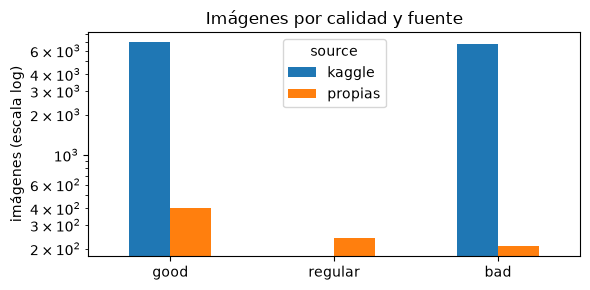

In [4]:
print('Proporción de cada clase dentro de cada fuente:')
display(pd.crosstab(sp.source, sp.quality, normalize='index').reindex(columns=config.QUALITY_CLASSES).round(3))

fig, ax = plt.subplots(figsize=(6, 3))
pd.crosstab(sp.quality, sp.source).reindex(config.QUALITY_CLASSES).plot.bar(ax=ax, rot=0, logy=True)
ax.set_ylabel('imágenes (escala log)'); ax.set_xlabel(''); ax.set_title('Imágenes por calidad y fuente')
plt.tight_layout(); plt.savefig(config.FIGURES_DIR / 'eda_clases.svg'); plt.show()

## 2. Resolución y formato de las imágenes

In [5]:
def dims(p):
    with Image.open(config.ROOT / p) as im:   # solo lee la cabecera, no la imagen completa
        return im.size

sp['w'], sp['h'] = zip(*[dims(p) for p in sp.path])
sp['mpx'] = sp.w * sp.h / 1e6
sp['orientacion'] = np.where(sp.w >= sp.h, 'horizontal', 'vertical')
print('Formatos:', sp.path.str.rsplit('.', n=1).str[-1].str.lower().value_counts().to_dict())
display(sp.groupby('source')[['w', 'h', 'mpx']].describe().T.round(2))
pd.crosstab(sp.source, sp.orientacion)

Formatos: {'jpg': 14546}


source       kaggle  propias
w   count  13696.00   850.00
    mean     273.85  2811.80
    std      445.70  1220.32
    min      144.00    19.00
    25%      192.00  1314.75
    50%      256.00  3024.00
    75%      256.00  4000.00
    max     8000.00  4032.00
h   count  13696.00   850.00
    mean     286.48  2738.60
    std      408.30  1100.15
    min      144.00    26.00
    25%      256.00  1600.00
    50%      256.00  3024.00
    75%      256.00  4032.00
    max     6000.00  4032.00
mpx count  13696.00   850.00
    mean       0.25     8.56
    std        2.58     4.55
    min        0.04     0.00
    25%        0.05     1.92
    50%        0.07    12.19
    75%        0.07    12.19
    max       48.00    12.19

orientacion,horizontal,vertical
source,,
kaggle,9737,3959
propias,387,463


## 3. Muestras visuales por clase y fuente
Para *good* y *bad*: tres fotos de Kaggle y tres propias. *Regular* solo existe en las fotos propias.

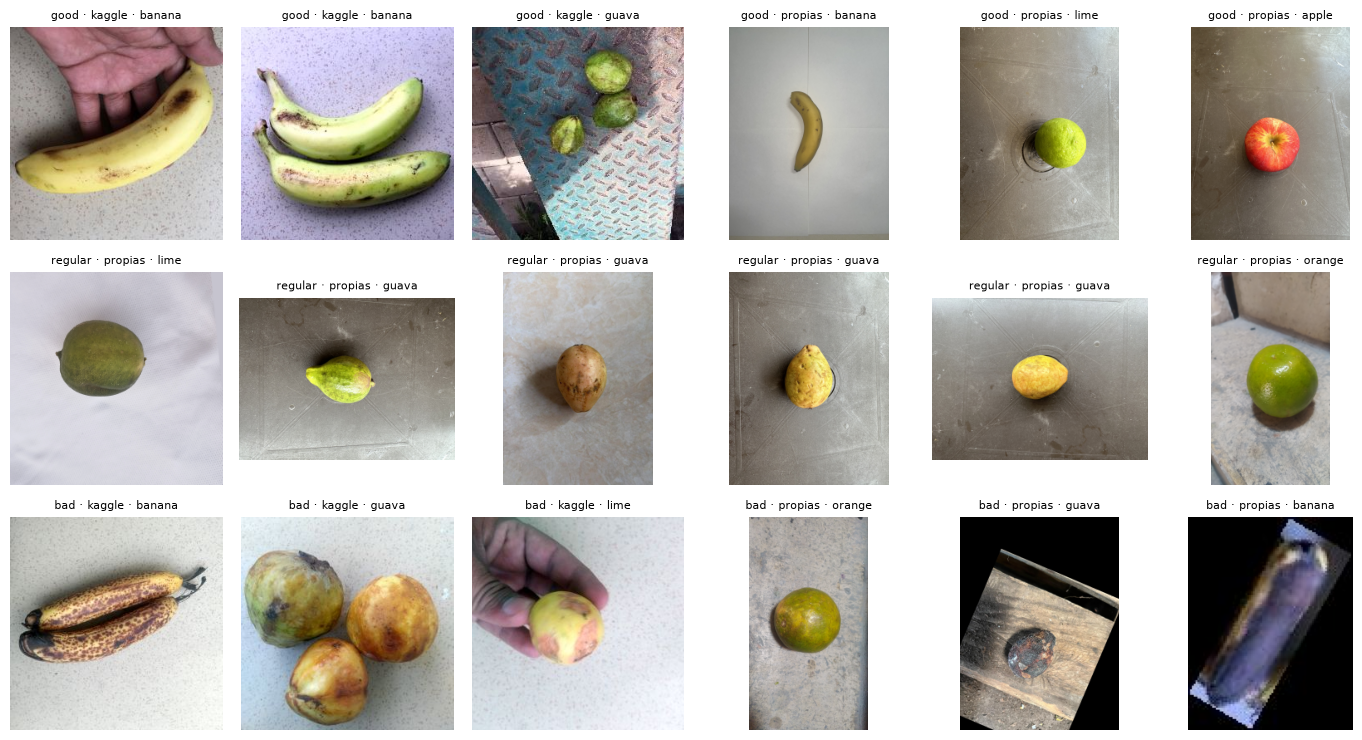

In [6]:
fig, axes = plt.subplots(3, 6, figsize=(14, 7.5))
for r, q in enumerate(config.QUALITY_CLASSES):
    sub = sp[sp.quality == q]
    kg = sub[sub.source == 'kaggle']
    k = kg.sample(min(3, len(kg)), random_state=0)
    pr = sub[sub.source == 'propias'].sample(6 - len(k), random_state=0)
    for ax, (_, row) in zip(axes[r], pd.concat([k, pr]).iterrows()):
        ax.imshow(cv2.cvtColor(load_image(config.ROOT / row.path, 256), cv2.COLOR_BGR2RGB))
        ax.set_title(f'{q} · {row.source} · {row.fruit}', fontsize=8)
    for ax in axes[r]:
        ax.axis('off')
plt.tight_layout(); plt.show()

## 4. Calidad de la segmentación
La segmentación (HSV + Otsu) se marca como dudosa (`seg_ok = False`) cuando no encuentra primer plano, cuando el contorno toca el borde de la foto en más del 15 % de su perímetro o cuando su solidez es menor que 0.7. En esos casos la app no reporta tamaño.

seg_ok,False,True,total,% válida
source,,,,
kaggle,1693,12003,13696,87.6
propias,83,767,850,90.2
total,1776,12770,14546,87.8


seg_ok               dudosa  válida
source  fruit                      
kaggle  apple         0.093   0.907
        banana        0.235   0.765
        guava         0.084   0.916
        lime          0.093   0.907
        orange        0.028   0.972
        pomegranate   0.211   0.789
propias apple         0.066   0.934
        banana        0.164   0.836
        granadilla    0.000   1.000
        guava         0.117   0.883
        lime          0.101   0.899
        orange        0.054   0.946

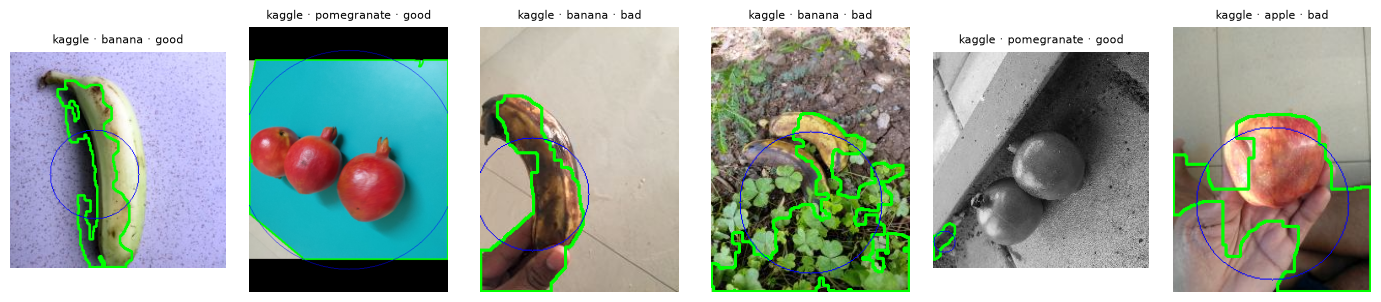

In [7]:
seg = pd.crosstab(sp.source, sp.seg_ok, margins=True, margins_name='total')
seg['% válida'] = (100 * seg[True] / seg['total']).round(1)
display(seg)
display(pd.crosstab([sp.source, sp.fruit], sp.seg_ok, normalize='index').round(3)
        .rename(columns={True: 'válida', False: 'dudosa'}))

dudosas = sp[~sp.seg_ok].sample(6, random_state=1)
fig, axes = plt.subplots(1, 6, figsize=(14, 3))
for ax, (_, row) in zip(axes, dudosas.iterrows()):
    img = load_image(config.ROOT / row.path)
    ax.imshow(cv2.cvtColor(overlay(img, segment(img)), cv2.COLOR_BGR2RGB)); ax.axis('off')
    ax.set_title(f'{row.source} · {row.fruit} · {row.quality}', fontsize=8)
plt.tight_layout(); plt.show()

## 5. Variabilidad de color y brillo entre fuentes
Se mide en los recortes de 128×128 (fondo en negro), solo sobre los píxeles de la fruta: saturación (S) y brillo (V) medios. Para que las dos fuentes pesen igual, se comparan las 850 fotos propias con 850 de Kaggle tomadas al azar (solo segmentaciones válidas). Si las fuentes se distinguen por el color, un modelo puede aprender la fuente en vez de la calidad.

S      V
source  quality              
kaggle  bad      145.4  142.3
        good     166.4  143.5
propias bad      127.4  133.0
        good     173.0  173.6
        regular  167.3  149.4

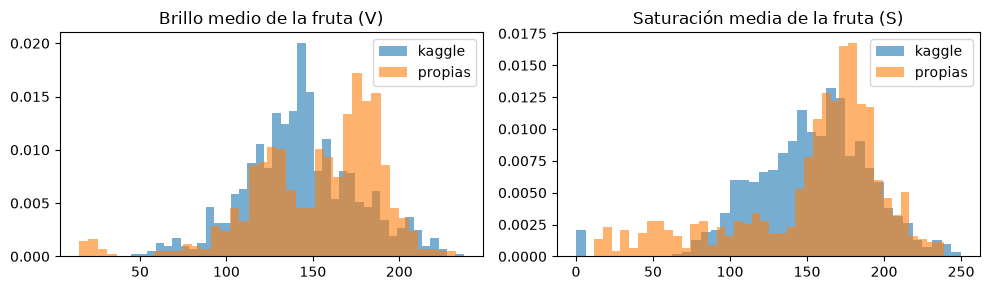

In [8]:
def color_medio(crop_path):
    hsv = cv2.cvtColor(cv2.imread(str(config.ROOT / crop_path)), cv2.COLOR_BGR2HSV)
    fruta = hsv[..., 2] > 10          # el fondo del recorte es negro
    return hsv[..., 1][fruta].mean(), hsv[..., 2][fruta].mean()

validas = sp[sp.seg_ok]
muestra = pd.concat([validas[validas.source == 'kaggle'].sample(850, random_state=0),
                     validas[validas.source == 'propias']])
muestra['S'], muestra['V'] = zip(*[color_medio(c) for c in muestra.crop])
display(muestra.groupby(['source', 'quality'])[['S', 'V']].median().round(1))

fig, axes = plt.subplots(1, 2, figsize=(10, 3))
titulos = {'V': 'Brillo medio de la fruta (V)', 'S': 'Saturación media de la fruta (S)'}
for ax, canal in zip(axes, ['V', 'S']):
    for fuente, g in muestra.groupby('source'):
        ax.hist(g[canal], bins=40, alpha=0.6, density=True, label=fuente)
    ax.set_title(titulos[canal]); ax.legend()
plt.tight_layout(); plt.savefig(config.FIGURES_DIR / 'eda_color_fuente.svg'); plt.show()

## 6. Tamaño (d_norm) por fruta y fuente
Si las fotos propias se tomaron a otra distancia, sus `d_norm` no son comparables con los de Kaggle. Por eso los terciles de tamaño se calculan por fuente y por fruta.

source,kaggle,propias
fruit,,
apple,0.623,0.515
banana,0.640,0.461
granadilla,NaN,0.478
guava,0.546,0.408
lime,0.558,0.360
orange,0.607,0.591
pomegranate,0.574,NaN


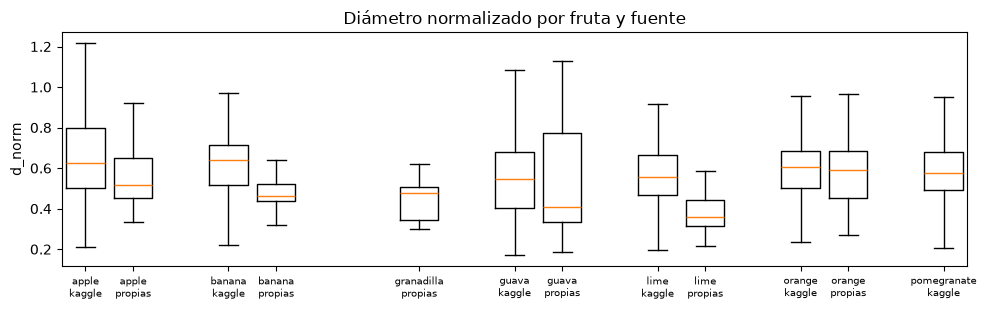

size                 pequeno  mediano  grande
source  fruit                                
kaggle  apple            764      763     763
        banana           734      733     733
        guava            761      760     760
        lime             727      726     726
        orange           787      786     786
        pomegranate      796      795     796
propias apple             66       65      65
        banana            51       50      51
        granadilla         6        6       6
        guava             66       65      65
        lime              47       46      46
        orange            50       49      50

In [9]:
ok = sp[sp.seg_ok]
display(ok.groupby(['fruit', 'source']).d_norm.median().unstack().round(3))

fig, ax = plt.subplots(figsize=(10, 3.2))
pos, datos, etiquetas = [], [], []
for i, f in enumerate(sorted(ok.fruit.unique())):
    for j, s in enumerate(['kaggle', 'propias']):
        d = ok[(ok.fruit == f) & (ok.source == s)].d_norm
        if len(d):
            pos.append(3 * i + j); datos.append(d); etiquetas.append(f'{f}\n{s}')
ax.boxplot(datos, positions=pos, widths=0.8, showfliers=False)
ax.set_xticks(pos); ax.set_xticklabels(etiquetas, fontsize=7); ax.set_ylabel('d_norm')
ax.set_title('Diámetro normalizado por fruta y fuente')
plt.tight_layout(); plt.savefig(config.FIGURES_DIR / 'eda_tamano.svg'); plt.show()

pd.crosstab([sp.source, sp.fruit], sp['size']).reindex(columns=['pequeno', 'mediano', 'grande'])

## 7. Fotos casi duplicadas y partición
FruitNet fotografía cada fruta desde varias direcciones, y en nuestras fotos hay ráfagas y copias rotadas. Si esas fotos quedan repartidas entre entrenamiento y prueba, el modelo las reconoce de memoria. ¿Cuántas fotos comparten grupo con otras?

In [10]:
tam = sp.groupby('group').agg(n=('path', 'size'), source=('source', 'first'))
res = tam.groupby('source').agg(grupos=('n', 'size'), fotos=('n', 'sum'), max_por_grupo=('n', 'max'))
res['fotos en grupos de 2+'] = tam[tam.n > 1].groupby('source').n.sum()
res['% en grupos de 2+'] = (100 * res['fotos en grupos de 2+'] / res.fotos).round(1)
display(res)
print('Grupos repartidos en más de un conjunto:', int((sp.groupby('group').split.nunique() > 1).sum()))
pd.crosstab([sp.source, sp.quality], sp.split, margins=True, margins_name='total')[['train', 'val', 'test', 'total']]

,grupos,fotos,max_por_grupo,fotos en grupos de 2+,% en grupos de 2+
source,,,,,
kaggle,8161,13696,97,6912,50.5
propias,443,850,16,536,63.1


Grupos repartidos en más de un conjunto: 0


split            train   val  test  total
source  quality                          
kaggle  bad       4834   922  1032   6788
        good      4974   979   955   6908
propias bad        150    31    29    210
        good       277    66    59    402
        regular    180    35    23    238
total            10415  2033  2098  14546

## 8. Hallazgos

Cada hallazgo justifica una decisión de preparación o de evaluación.

1. **Desbalance y una clase que solo existe en una fuente.** Kaggle trae solo *good* y *bad*, casi 50/50, más 1 074 fotos *mixed* que no usamos. *Regular* solo existe en nuestras fotos: 238 de 14 546 imágenes (1.6 %). Dentro de las fotos propias hay 47 % *good*, 28 % *regular* y 25 % *bad*, y la manzana *bad* tiene solo 3 fotos. **Decisión:** pesos por clase $w_k = N/(K N_k)$, F1 macro como métrica principal y todos los resultados separados por fuente.
2. **Resoluciones muy distintas.** Las fotos de Kaggle son pequeñas (mediana de 256×256 px, 0.07 MP). Las nuestras son de celular (mediana de 3 024 px de lado, 12 MP), y el 54 % son verticales. Además, 26 fotos propias miden menos de 128 px. **Decisión:** todas se reducen a 512 px en su lado mayor y se recortan a 128×128, para que el tamaño del archivo no sea una pista de la fuente.
3. **La segmentación falla en el 12 % de las fotos.** Es válida en el 87.6 % de Kaggle y en el 90.2 % de las propias. Las peores frutas son el banano (23.5 % dudosas en Kaggle), que es alargado y suele tocar el borde de la foto, y la granada (21.1 %). La muestra de la sección 3 también muestra que muchas fotos de Kaggle no cumplen la entrada de la consigna: tienen dos o tres frutas o una mano. En esos casos la segmentación se queda con la región más saturada. **Decisión:** cuando la segmentación es dudosa, la app no reporta tamaño y lo avisa.
4. **Las fuentes se distinguen por la luz.** Dentro de la fruta, el brillo mediano (V) de las *good* propias es 174, contra 144 en las *good* de Kaggle. Las *bad* propias tienen menos saturación (127 contra 145). Borrar el fondo no basta, porque la luz sobre la fruta sigue delatando la fuente. **Decisión:** reportar todo por fuente. Más adelante el detector de fuente (AUC de 0.96) y la proyección LDA confirmaron este riesgo de atajo.
5. **En nuestras fotos la fruta ocupa menos cuadro.** La mediana de $d_{norm}$ va de 0.55 a 0.64 en Kaggle y de 0.36 a 0.59 en las fotos propias. **Decisión:** los terciles de tamaño se calculan por fuente y por fruta, y así cada combinación queda con tres clases balanceadas.
6. **Muchas fotos casi duplicadas.** El 50.5 % de las fotos de Kaggle y el 63.1 % de las propias comparten grupo con otras fotos de la misma fruta. Un grupo de Kaggle tiene 97 fotos. **Decisión:** partición 70/15/15 agrupada; ningún grupo queda repartido entre entrenamiento, validación y prueba.
7. **Copias que la partición no agrupó.** `banana_001_*` (17 archivos) y `banana_002_*` (11) son recortes, rotaciones y cambios de color de solo dos fotos de banano *bad*. No llevan el sufijo `_aug_N` y la similitud de miniaturas no las juntó, así que 4 de las 29 *bad* propias de prueba tienen copias en entrenamiento. No cambian las conclusiones: el SVM falla 3 de esas 4 y XGBoost ninguna. Corregirlo exige volver a partir y reentrenar, y queda reportado como limitación.
